# Deriva: las reglas del PSI, su valor de referencia y la tasa de falsas alarmas

**Pregunta:** ¿Con qué frecuencia las reglas empíricas del PSI dan una falsa alarma cuando nada ha cambiado, y qué tan grande debe ser un desplazamiento para que ellas, la referencia chi-cuadrado y la prueba de Kolmogorov-Smirnov lo detecten?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 02 de este tema (la tasa y el tamaño de cada prueba)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir por qué el índice de estabilidad poblacional (PSI) tiene un piso de ruido que depende solo de los tamaños de muestra, y calcularlo junto con el valor de referencia al 5 % del motor;
- leer el PSI, su banda convencional y su valor p en tres conjuntos y ver cuándo la banda y la referencia discrepan;
- medir la tasa de falsas alarmas de las dos reglas empíricas cuando nada ha cambiado y ver cómo cae con el tamaño de muestra;
- dibujar la potencia de las reglas, de la referencia chi-cuadrado y de la prueba de Kolmogorov-Smirnov frente al tamaño del desplazamiento;
- repetir celdas de la tabla 4 de Yurdakul y Naranjo (2020) con el motor y distinguir la deriva de la descalibración.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son la familia `drift` del caso C22, validar al validador. Su panel `stability` sortea dos muestras de una variable según el diseño de Yurdakul y Naranjo (2020): una muestra base de $N(0, 8^2)$ clasificada en sus diez deciles poblacionales, y una muestra actual cuya media se desplaza una fracción de desviación estándar, en una escalera de 0 a 0,5. Su panel `calibration` desplaza las covariables de una cartera logística en las mismas cantidades mientras el modelo conserva sus coeficientes verdaderos. Cada conjunto lo sortea un generador de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`). La familia guarda también, en `golden`, las 54 celdas de la tabla 4 del artículo, citadas de él.

- **Archivo que se lee:** `data/derived/C22/drift.json`, claves `outputs` (simulaciones, generadores, escalera, celdas publicadas) y `provenance`.
- **Qué se toma de él:** la escalera, la configuración y la semilla de cada peldaño y las tasas publicadas.

La celda siguiente carga el archivo e imprime la escalera con las versiones del motor.

In [2]:
# Cargar la familia de deriva e indexar sus simulaciones por clave
LANG = "es"
ROOT = Path("../../..").resolve()
drift = json.loads((ROOT / "data" / "derived" / "C22" / "drift.json").read_text(encoding="utf-8"))
out = drift["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
ladder = out["ladder"]["values"]
golden = out["golden"][0]
print("desplazamientos de la escalera, en desviaciones estándar:", ladder)
print("calculado con riskvalidation", drift["provenance"]["riskvalidation_version"], "|", "instalado", rv.__version__)

desplazamientos de la escalera, en desviaciones estándar: [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]
calculado con riskvalidation 1.0.1 | instalado 1.0.1


## Método

**El PSI.** Con $B$ intervalos fijos, proporciones de desarrollo $e_i$ y proporciones actuales $a_i$, el índice es

$$\mathrm{PSI} = \sum_{i=1}^{B} (a_i - e_i)\,\ln\frac{a_i}{e_i},$$

la divergencia de Kullback-Leibler simetrizada. La práctica lo lee con dos reglas empíricas, 0,10 para un cambio pequeño y 0,25 para uno significativo. Yurdakul y Naranjo muestran que para muestras de $n$ y $m$ observaciones el índice es aproximadamente $(1/n + 1/m)\,\chi^2_{B-1}$ cuando nada cambia, de modo que su valor esperado es $(1/n + 1/m)(B-1)$ y una prueba de nivel $\alpha$ rechaza sobre $(1/n + 1/m)\,\chi^2_{1-\alpha,\,B-1}$. Una banda fija ignora el tamaño de muestra y la referencia lo sigue. Los pasos calculan ambas, sortean conjuntos, miden las falsas alarmas y la potencia de las reglas, repiten la tabla del artículo y contrastan la deriva con la descalibración.

### Paso 1: el piso de ruido del PSI

Con diez intervalos, el PSI esperado cuando nada cambia es $(1/n + 1/m)\cdot 9$. El `psi_benchmark` del motor devuelve la referencia al 5 % para tamaños de muestra dados. La celda siguiente imprime ambos para cuatro tamaños de muestra iguales, y los dibuja contra las dos reglas empíricas en un eje logarítmico.

n = m =  100 | PSI esperado sin cambio 0.1800 | referencia al 5 % 0.3384
n = m =  200 | PSI esperado sin cambio 0.0900 | referencia al 5 % 0.1692
n = m =  400 | PSI esperado sin cambio 0.0450 | referencia al 5 % 0.0846
n = m = 1000 | PSI esperado sin cambio 0.0180 | referencia al 5 % 0.0338


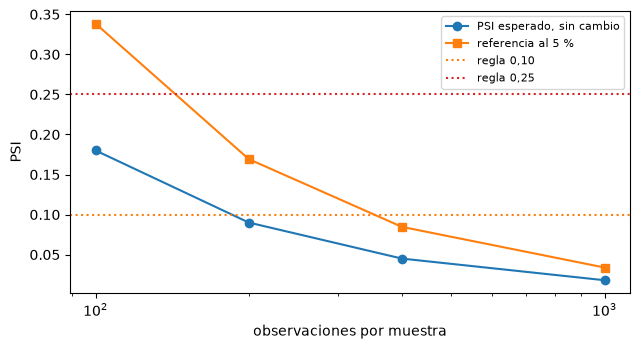

In [3]:
# PSI esperado cuando nada cambia y valor de referencia al 5 % del motor, para cuatro tamaños de muestra
from riskvalidation.validation.stability import psi_benchmark

sizes = (100, 200, 400, 1000)
floor = [(1 / n + 1 / n) * 9 for n in sizes]
benchmark = [psi_benchmark(n, n) for n in sizes]
for n, f, b in zip(sizes, floor, benchmark):
    print(f"n = m = {n:4d} | PSI esperado sin cambio {f:.4f} | referencia al 5 % {b:.4f}")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(sizes, floor, "o-", label="PSI esperado, sin cambio")
ax.plot(sizes, benchmark, "s-", label="referencia al 5 %")
ax.axhline(0.10, color="tab:orange", linestyle=":", label="regla 0,10")
ax.axhline(0.25, color="tab:red", linestyle=":", label="regla 0,25")
ax.set_xscale("log")
ax.set_xlabel("observaciones por muestra")
ax.set_ylabel("PSI")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Con 100 observaciones por muestra el PSI esperado cuando nada cambia es 0,1800, ya sobre la regla de 0,10, y la referencia al 5 % es 0,3384, sobre incluso la regla de 0,25. Con 1.000 observaciones el piso baja a 0,0180 y la referencia a 0,0338. Las dos líneas bajan con el tamaño de muestra mientras las reglas punteadas quedan quietas, de modo que una banda fija corta el ruido en muestras pequeñas y queda muy por encima de la señal en las grandes. La referencia es la única de las tres que se mueve con la información de los datos.

### Paso 2: cuánto vale un desplazamiento en unidades de PSI

El generador `TwoSample` declara en su `truth()` la distribución poblacional de ambas muestras, de modo que el PSI de un desplazamiento se calcula sin muestreo con `population_psi`. El tamaño de muestra en que una regla empírica iguala la referencia al 5 % sale de $(2/n)\,\chi^2_{0.95,\,9} = \text{banda}$. La celda siguiente imprime el PSI poblacional de cada peldaño de la escalera y ese tamaño de muestra para las dos reglas.

In [4]:
# PSI poblacional de cada desplazamiento de la escalera y tamaño de muestra en que cada regla iguala la referencia
from riskvalidation.generators.drift import TwoSample, population_psi

for shift in ladder:
    truth = TwoSample(1000, 1000, shift=shift).truth()
    psi_pop = population_psi(truth["bins_base"], truth["bins_target"])
    print(f"desplazamiento {shift:4.2f} | PSI poblacional {psi_pop:.4f}")
critical = stats.chi2.ppf(0.95, 9)
for band in (0.10, 0.25):
    print(f"regla empírica {band:.2f} | iguala la referencia al 5 % con n = m = {2 * critical / band:.0f}")

desplazamiento 0.00 | PSI poblacional 0.0000
desplazamiento 0.05 | PSI poblacional 0.0024
desplazamiento 0.10 | PSI poblacional 0.0096
desplazamiento 0.20 | PSI poblacional 0.0383
desplazamiento 0.30 | PSI poblacional 0.0861
desplazamiento 0.50 | PSI poblacional 0.2377
regla empírica 0.10 | iguala la referencia al 5 % con n = m = 338
regla empírica 0.25 | iguala la referencia al 5 % con n = m = 135


Un desplazamiento de media desviación estándar tiene un PSI poblacional de 0,2377, todavía bajo la regla de 0,25, de modo que ni una muestra enorme activaría esa banda con ese desplazamiento. Uno de 0,2 desviaciones estándar vale solo 0,0383. Las reglas y la referencia coinciden con muestras de 338 observaciones para la regla de 0,10 y 135 para la de 0,25: bajo esos tamaños la regla es más estricta que la referencia y se activa con ruido, sobre ellos es más laxa y deja pasar desplazamientos reales.

### Paso 3: tres conjuntos, tres lecturas

`stability_psi` recibe los conteos por intervalo de las dos muestras y devuelve un `TestResult` con el PSI como métrica, el valor p chi-cuadrado, la banda convencional en sus notas y la referencia al 5 % en sus extras. La celda siguiente sortea tres conjuntos con una semilla fija: dos muestras de 100 sin cambio, dos de 1.000 sin cambio y dos de 1.000 cuyas medias difieren en 0,2 desviaciones estándar.

In [5]:
# Sortear tres conjuntos y leer en cada uno el PSI, su banda convencional, su referencia y su valor p
from riskvalidation.validation.stability import stability_psi

cases = (("100 vs 100", TwoSample(100, 100)), ("1000 vs 1000", TwoSample(1000, 1000)),
         ("1000 vs 1000, desplazamiento 0,2", TwoSample(1000, 1000, shift=0.2)))
for label, generator in cases:
    sample = generator.draw(np.random.default_rng(31))
    result = stability_psi(sample["expected_counts"], sample["actual_counts"])
    print(f"{label:34s} PSI {result.metric:.4f} | banda {result.extras['band']}")
    print(f"{'':34s} referencia {result.extras['benchmark_05']:.4f} | p {result.p_value:.4f}")

100 vs 100                         PSI 0.2796 | banda significant change
                                   referencia 0.3384 | p 0.1231
1000 vs 1000                       PSI 0.0146 | banda little change
                                   referencia 0.0338 | p 0.6047
1000 vs 1000, desplazamiento 0,2   PSI 0.0392 | banda little change
                                   referencia 0.0338 | p 0.0205


Dos muestras de 100 sin cambio dan un PSI de 0,2796, que la banda convencional llama cambio significativo, mientras la referencia de 0,3384 y un valor p de 0,1231 ven correctamente ruido. Las muestras de 1.000 sin cambio dan 0,0146 y un valor p de 0,6047. Con un desplazamiento real de 0,2 desviaciones estándar el PSI es 0,0392, en la banda de cambio pequeño, pero sobre la referencia de 0,0338 con un valor p de 0,0205: la banda omite lo que la prueba ve. El mismo índice lleva a errores opuestos en las dos direcciones.

### Paso 4: las falsas alarmas de las reglas, medidas

La celda siguiente corre la prueba del PSI sobre dos muestras sin cambio con cuatro tamaños de muestra, 4.000 repeticiones cada uno, con el `simulate` del motor y dos reglas adicionales construidas con `metric_above`: el PSI supera 0,10 y el PSI supera 0,25. Imprime la tasa de falsas alarmas de ambas reglas y de la referencia al 5 % en cada tamaño y las dibuja.

n = m =  100 | PSI > 0.10 0.857 | PSI > 0.25 0.227 | referencia al 5 % 0.075
n = m =  200 | PSI > 0.10 0.379 | PSI > 0.25 0.004 | referencia al 5 % 0.061
n = m =  400 | PSI > 0.10 0.021 | PSI > 0.25 0.000 | referencia al 5 % 0.052
n = m = 1000 | PSI > 0.10 0.000 | PSI > 0.25 0.000 | referencia al 5 % 0.049


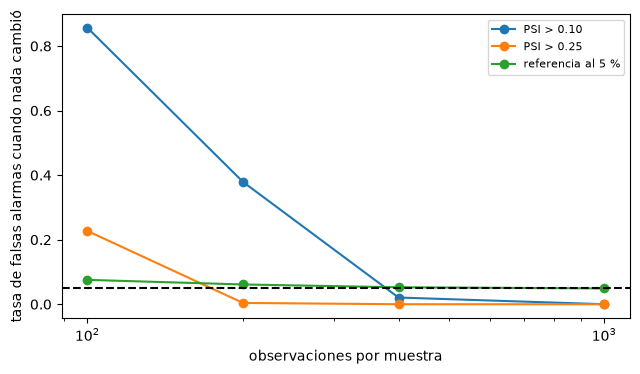

In [6]:
# Medir la tasa de falsas alarmas de las dos reglas empíricas y de la referencia con cuatro tamaños de muestra
from riskvalidation.harness.run import metric_above, simulate

rules = (metric_above(0.10, "metric>0.1"), metric_above(0.25, "metric>0.25"))
names = {"metric>0.1": "PSI > 0.10", "metric>0.25": "PSI > 0.25", "p<0.05": "referencia al 5 %"}
alarms = {rule: [] for rule in names}
for n in (100, 200, 400, 1000):
    run = simulate("stability.psi", TwoSample(n, n), n_rep=4000, seed=2026, rules=rules)
    for rule in names:
        alarms[rule].append(run.rates[rule])
    print(f"n = m = {n:4d} |", " | ".join(f"{names[rule]} {alarms[rule][-1].rate:.3f}" for rule in names))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for rule, label in names.items():
    ax.plot((100, 200, 400, 1000), [r.rate for r in alarms[rule]], "o-", label=label)
ax.axhline(0.05, color="black", linestyle="--")
ax.set_xscale("log")
ax.set_xlabel("observaciones por muestra")
ax.set_ylabel("tasa de falsas alarmas cuando nada cambió")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Con muestras de 100 la regla de 0,10 se activa el 0,857 de las veces cuando nada cambió y la de 0,25 el 0,227, frente a 0,075 de la referencia. Con 200 las reglas dan 0,379 y 0,004, con 400 dan 0,021 y 0,000, y con 1.000 ambas callan. La referencia queda cerca de su nivel en todos los tamaños, entre 0,075 y 0,049, algo sobre 5 % en las muestras más chicas porque su forma chi-cuadrado es asintótica. Las reglas pasan de dar una falsa alarma en seis casos de siete a no darla nunca, y cruzan la línea de 5 % en el medio.

### Paso 5: potencia a lo largo de la escalera

Con muestras de 1.000, la celda siguiente mueve la media de la muestra actual a lo largo de la escalera y simula el PSI con sus dos reglas y su referencia, la prueba chi-cuadrado de homogeneidad y la prueba de Kolmogorov-Smirnov, 1.000 repeticiones por peldaño. Imprime la tasa a la que se activa cada una y dibuja las cinco curvas. El primer peldaño, sin desplazamiento, es la tasa de falsas alarmas y los demás son potencia.

PSI > 0.10                   [0.0, 0.0, 0.0, 0.026, 0.523, 1.0]
PSI > 0.25                   [0.0, 0.0, 0.0, 0.0, 0.0, 0.557]
PSI con referencia           [0.042, 0.101, 0.262, 0.898, 1.0, 1.0]
chi-square                   [0.041, 0.097, 0.257, 0.894, 1.0, 1.0]
Kolmogorov-Smirnov           [0.051, 0.126, 0.49, 0.968, 1.0, 1.0]


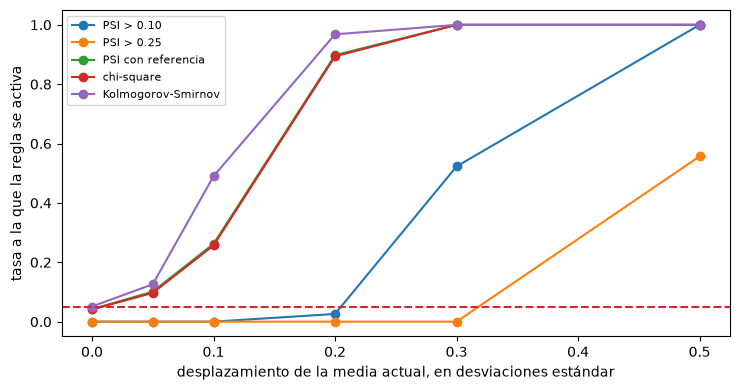

In [7]:
# Potencia de cada regla y prueba a lo largo de la escalera de desplazamientos, muestras de 1000
curves = {"PSI > 0.10": ("stability.psi", "metric>0.1"), "PSI > 0.25": ("stability.psi", "metric>0.25"),
          "PSI con referencia": ("stability.psi", "p<0.05"), "chi-square": ("stability.chi2", "p<0.05"),
          "Kolmogorov-Smirnov": ("stability.ks", "p<0.05")}
power = {name: [] for name in curves}
for shift in ladder:
    row = rows[f"stability.psi@s{shift:g}"]
    sample_gen = TwoSample(1000, 1000, shift=shift)
    runs = {}
    for test in ("stability.psi", "stability.chi2", "stability.ks"):
        runs[test] = simulate(test, sample_gen, n_rep=1000, seed=row["seed"], rules=rules)
    for name, (test, rule) in curves.items():
        power[name].append(runs[test].rates[rule].rate)
fig, ax = plt.subplots(figsize=(7.5, 4))
for name in curves:
    ax.plot(ladder, power[name], "o-", label=name)
    print(f"{name:28s}", [round(p, 3) for p in power[name]])
ax.axhline(0.05, color="tab:red", linestyle="--")
ax.set_xlabel("desplazamiento de la media actual, en desviaciones estándar")
ax.set_ylabel("tasa a la que la regla se activa")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Con un desplazamiento de 0,2 desviaciones estándar la referencia se activa el 0,898 de las veces, la prueba chi-cuadrado el 0,894 y la de Kolmogorov-Smirnov el 0,968, mientras la regla de 0,10 se activa el 0,026 y la de 0,25 nunca. La regla de 0,10 necesita un desplazamiento de 0,3 para llegar a 0,523, y la de 0,25 no se activa más de la mitad de las veces ni con 0,5, con 0,557. Con 0,1 la prueba de Kolmogorov-Smirnov ya detecta 0,490 frente a 0,262 de la referencia. Con estas muestras las reglas empíricas son casi ciegas donde las pruebas ven, y un desplazamiento que ellas omiten es invisible solo para ellas.

### Paso 6: la tabla 4 del artículo, repetida

Yurdakul y Naranjo (2020) imprimieron, con 10.000 corridas, la tasa a la que se activan las dos reglas empíricas y la referencia chi-cuadrado para seis pares de tamaños de muestra y tres desplazamientos. La celda siguiente repite las celdas de muestras iguales (100, 200 y 400 observaciones; desplazamientos de 0 y un cuarto de desviación estándar) con 4.000 repeticiones y una semilla nueva, y pone cada tasa junto a la publicada con `agrees_with_published`. La última línea da el conteo de la tabla del archivo.

In [8]:
# Repetir celdas de la tabla 4 de Yurdakul y Naranjo con el motor y ponerlas junto a las tasas publicadas
from riskvalidation.harness.rates import agrees_with_published

cells = {(c["row"], c["column"]): c["published"] for c in golden["cells"]}
for size_m, size_n in ((100, 100), (200, 200), (400, 400)):
    for shift in (0.0, 0.25):
        run = simulate("stability.psi", TwoSample(size_n, size_m, shift=shift), n_rep=4000, seed=7, rules=rules)
        for rule, column in (("metric>0.1", "PSI > 0.10"), ("metric>0.25", "PSI > 0.25"), ("p<0.05", "chi-square")):
            published = cells[(f"m {size_m}, n {size_n}", f"shift {shift:g} SD, {column}")]
            ok, z = agrees_with_published(run.rates[rule], published, golden["runs_published"])
            print(f"m {size_m}, n {size_n} | {shift:4.2f} | {column:10s} | publicado {published:.3f}", end=" | ")
            print(f"corrida nueva {run.rates[rule].rate:.4f} | z {z:+.2f} | {ok}")
print("celdas de la tabla en el archivo:", len(golden["cells"]), "| que concuerdan:", golden["agree"])

m 100, n 100 | 0.00 | PSI > 0.10 | publicado 0.849 | corrida nueva 0.8588 | z +1.47 | True
m 100, n 100 | 0.00 | PSI > 0.25 | publicado 0.233 | corrida nueva 0.2268 | z -0.79 | True
m 100, n 100 | 0.00 | chi-square | publicado 0.076 | corrida nueva 0.0745 | z -0.30 | True
m 100, n 100 | 0.25 | PSI > 0.10 | publicado 0.943 | corrida nueva 0.9380 | z -1.14 | True
m 100, n 100 | 0.25 | PSI > 0.25 | publicado 0.459 | corrida nueva 0.4552 | z -0.40 | True
m 100, n 100 | 0.25 | chi-square | publicado 0.218 | corrida nueva 0.2220 | z +0.52 | True
m 200, n 200 | 0.00 | PSI > 0.10 | publicado 0.369 | corrida nueva 0.3550 | z -1.55 | True
m 200, n 200 | 0.00 | PSI > 0.25 | publicado 0.004 | corrida nueva 0.0032 | z -0.65 | True
m 200, n 200 | 0.00 | chi-square | publicado 0.057 | corrida nueva 0.0555 | z -0.35 | True
m 200, n 200 | 0.25 | PSI > 0.10 | publicado 0.775 | corrida nueva 0.7800 | z +0.64 | True
m 200, n 200 | 0.25 | PSI > 0.25 | publicado 0.085 | corrida nueva 0.0910 | z +1.14 | True

Las 18 celdas repetidas concuerdan con el artículo, con diferencias estandarizadas entre -1,55 y +1,47. La lectura del artículo se mantiene en ellas: la regla de 0,10 tiene un error tipo I de 0,859 con 100 observaciones y 0,020 con 400, el de la regla de 0,25 cae de 0,227 a 0,000, y la referencia chi-cuadrado queda cerca de 5 %, de 0,075 a 0,051. En la tabla del archivo, que reúne las 54 celdas del artículo, 50 concuerdan. Los hallazgos cualitativos se reproducen, que es lo que la afirmación necesita.

### Paso 7: la deriva no es descalibración

El panel `calibration` desplaza las covariables de una cartera logística en las mismas cantidades mientras el modelo conserva sus coeficientes verdaderos, de modo que sus PD siguen siendo correctas para cada deudor. Una alarma de deriva y una de calibración responden preguntas distintas, y la segunda debería callar. La celda siguiente simula Hosmer-Lemeshow y Spiegelhalter a lo largo de la escalera, 500 repeticiones por peldaño, y dibuja sus tasas de rechazo contra el 5 % nominal.

pd.hosmer_lemeshow   [0.042, 0.064, 0.038, 0.056, 0.064, 0.046]
pd.spiegelhalter     [0.048, 0.044, 0.048, 0.056, 0.064, 0.054]


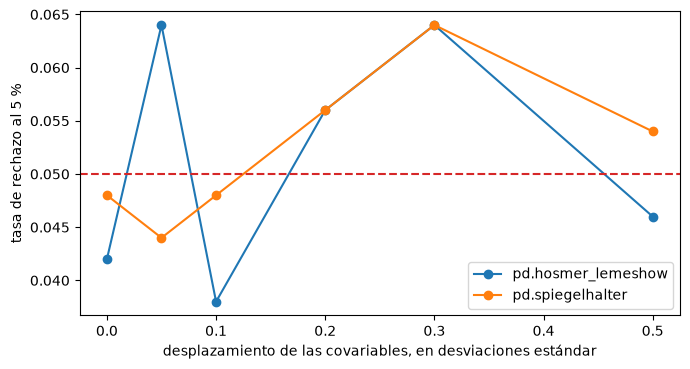

In [9]:
# Desplazar las covariables de un modelo logístico correcto y medir Hosmer-Lemeshow y Spiegelhalter
from riskvalidation.generators.scores import LogisticPortfolio

fig, ax = plt.subplots(figsize=(7, 3.8))
for test in ("pd.hosmer_lemeshow", "pd.spiegelhalter"):
    rates = []
    for shift in ladder:
        row = rows[f"{test}@s{shift:g}"]
        gen = LogisticPortfolio(**out["generators"][row["generator"]]["config"])
        rates.append(simulate(test, gen, n_rep=500, seed=row["seed"]).rates["p<0.05"].rate)
    ax.plot(ladder, rates, "o-", label=test)
    print(f"{test:20s}", [round(r, 3) for r in rates])
ax.axhline(0.05, color="tab:red", linestyle="--")
ax.set_xlabel("desplazamiento de las covariables, en desviaciones estándar")
ax.set_ylabel("tasa de rechazo al 5 %")
ax.legend()
fig.tight_layout()
plt.show()

Ambas pruebas de calibración se quedan en el nivel de un modelo correcto en toda la escalera: Hosmer-Lemeshow entre 0,038 y 0,064 y Spiegelhalter entre 0,044 y 0,064, con 500 repeticiones por peldaño, donde el error de Monte Carlo es de cerca de un punto. Las covariables derivaron media desviación estándar, un desplazamiento que la prueba de Kolmogorov-Smirnov detecta siempre en el paso anterior, y aun así las PD del modelo siguen siendo correctas para cada deudor. Un validador debe leer entonces una alarma de deriva como una razón para mirar, no como evidencia de descalibración.

## Resultados

**Respuesta:** Con 100 observaciones por muestra y nada cambiado, la regla empírica de 0,10 se activa el 0,857 de las veces y la de 0,25 el 0,227, frente a 0,075 de la referencia al 5 %; con 1.000 observaciones ambas reglas callan y la referencia queda en 0,049. En potencia con muestras de 1.000, un desplazamiento de 0,2 desviaciones estándar es detectado el 0,898 de las veces por la referencia y el 0,968 por la prueba de Kolmogorov-Smirnov, pero solo el 0,026 por la regla de 0,10 y nunca por la de 0,25, que llega a 0,557 con un desplazamiento de 0,5.

- **El piso de ruido depende del tamaño de muestra.** El PSI esperado sin cambio es 0,1800 para muestras de 100 y 0,0180 para 1.000; las reglas y la referencia coinciden con 338 y 135 observaciones.
- **El motor reproduce el artículo.** Las 18 celdas repetidas de la tabla 4 concuerdan, con diferencias estandarizadas de -1,55 a +1,47.
- **La deriva no es descalibración.** Con un modelo correcto, Hosmer-Lemeshow se mantiene entre 0,038 y 0,064 mientras las covariables se desplazan.

Cómo se comportan las mismas reglas cuando el cambio viene de una fuga o de un puntaje que decae es el tema del cuaderno siguiente.

## Resumen

- El PSI tiene un piso de ruido de $(1/n + 1/m)(B-1)$ y una referencia al 5 % de $(1/n + 1/m)\chi^2_{0.95,\,B-1}$, ambos dependientes de los tamaños de muestra; una banda fija no puede.
- La regla de 0,10 da falsas alarmas la mayor parte del tiempo con muestras de 100 y ninguna con 1.000, y la de 0,25 rara vez se activa incluso con un desplazamiento de media desviación estándar.
- La referencia chi-cuadrado mantiene su nivel y la prueba de Kolmogorov-Smirnov es la más potente de las cinco ante un desplazamiento de la media.
- El motor reproduce las celdas de muestras iguales de la tabla 4 del artículo.
- Una alarma de deriva no dice nada de la calibración cuando el modelo es correcto.

**Qué probar después.** Repite el paso 4 con una muestra base de 400 y una actual de 100 y mira qué regla cambia más; luego lee el cuaderno 06.

## Referencias

- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4): las reglas empíricas, el Teorema 3.3, la referencia y la Tabla 4. https://doi.org/10.21314/JRMV.2020.227
- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- Este repositorio: `docs/design/features/c22-validator/requirements.md` y `data-pipeline/pipeline/cases/c22_validator.py`, que escribió el artefacto.